In [1]:
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession
import kagglehub

/Users/marteinn/Documents/DataSci/BigData/project/Crop-Yield-Prediction-w-Spark/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("patelris/crop-yield-prediction-dataset")
print(path)

df = pd.read_csv(f"{path}/yield_df.csv", index_col=0)
df.head()

/Users/marteinn/.cache/kagglehub/datasets/patelris/crop-yield-prediction-dataset/versions/7


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [3]:
df.describe()

,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,28242.000000,28242.000000,28242.00000,28242.000000,28242.000000
mean,2001.544296,77053.332094,1149.05598,37076.909344,20.542627
std,7.051905,84956.612897,709.81215,59958.784665,6.312051
min,1990.000000,50.000000,51.00000,0.040000,1.300000
25%,1995.000000,19919.250000,593.00000,1702.000000,16.702500
50%,2001.000000,38295.000000,1083.00000,17529.440000,21.510000
75%,2008.000000,104676.750000,1668.00000,48687.880000,26.000000
max,2013.000000,501412.000000,3240.00000,367778.000000,30.650000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Area                           28242 non-null  str    
 1   Item                           28242 non-null  str    
 2   Year                           28242 non-null  int64  
 3   hg/ha_yield                    28242 non-null  int64  
 4   average_rain_fall_mm_per_year  28242 non-null  float64
 5   pesticides_tonnes              28242 non-null  float64
 6   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(2), str(2)
memory usage: 1.5 MB


In [5]:
df.columns

Index(['Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year',
       'pesticides_tonnes', 'avg_temp'],
      dtype='str')

Text(0, 0.5, 'Frequency')

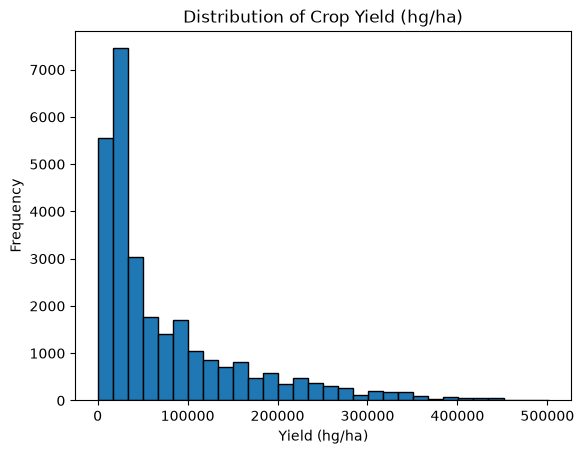

In [12]:
df['hg/ha_yield']

# Histogram of the yield column.
import matplotlib.pyplot as plt
plt.hist(df['hg/ha_yield'], bins=30, edgecolor='black')
plt.title('Distribution of Crop Yield (hg/ha)')
plt.xlabel('Yield (hg/ha)')
plt.ylabel('Frequency')

In [26]:
df.duplicated().sum()          # I believe this dataset has duplicate rows, but verify
#df.describe()                  # look for implausible mins/maxes
#df["average_rain_fall_mm_per_year"].min(), df["average_rain_fall_mm_per_year"].max()
#df.groupby("Item")["hg/ha_yield"].describe()

np.int64(2310)

In [19]:
test = df.groupby("avg_temp")["hg/ha_yield"]
test.duplicated().sum()          # I believe this dataset has duplicate rows, but verify

AttributeError: 'SeriesGroupBy' object has no attribute 'duplicated'